# Task 1: Time-Series Preprocessing, Exploratory Analysis and Forecasting Model
**Dataset:** Air Quality (UCI Machine Learning Repository, Kaggle copy), hourly readings from a gas multisensor device at road level in an Italian city.
**Target:** carbon monoxide concentration, `CO(GT)` in mg/m³, measured by a certified reference analyser.
**Problem:** forecast the **next hour's CO concentration** from the readings available now. An accurate short-term forecast lets a city warn residents before pollution peaks.

This notebook covers Task 1 of the group pipeline: understanding the data (A), six analytical questions (B), and a tuned forecasting model with an experiment table (C). The cleaning and feature functions are kept in one place so Task 4 (the forecast script) can reuse exactly the same preprocessing.

## 0. Setup
Run from the repository root, with the raw file at `data/AirQualityUCI.csv`. In Colab, upload the CSV into a `data/` folder first. Random seeds are fixed so the results can be repeated.

In [14]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
DATA_PATH = Path("data/AirQualityUCI.csv")
FIG_DIR, MODEL_DIR = Path("figures"), Path("models")
FIG_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)
TARGET = "CO(GT)"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## A. Understanding the dataset
### A1. Loading and structure
The file has two empty columns and blank rows at the end, which are removed. Date and time are joined into one `datetime` index. The dates are written month first (3/10/2004 is 10 March 2004).

In [15]:
def load_raw(path):
    df = pd.read_csv(path, encoding="utf-8-sig").dropna(how="all")
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")].dropna(subset=["Date"])
    df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%m/%d/%Y %H:%M:%S")
    return df.drop(columns=["Date", "Time"]).set_index("datetime").sort_index()

raw = load_raw(DATA_PATH)
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
raw.head()

Shape: (9357, 13)
Columns: ['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


### A2. Time range and frequency

In [16]:
steps = raw.index.to_series().diff().value_counts()
full_range = pd.date_range(raw.index.min(), raw.index.max(), freq="h")
print("First record:", raw.index.min())
print("Last record: ", raw.index.max())
print("Duration:    ", raw.index.max() - raw.index.min())
print("Time steps between records:\n", steps)
print("Missing timestamps in the hourly range:", len(full_range.difference(raw.index)))

First record: 2004-03-10 18:00:00
Last record:  2005-04-04 14:00:00
Duration:     389 days 20:00:00
Time steps between records:
 datetime
0 days 01:00:00    9356
Name: count, dtype: int64
Missing timestamps in the hourly range: 0


**Findings.** The data runs from **10 March 2004, 18:00 to 4 April 2005, 14:00**, about 390 days. It is recorded **hourly**: every step between records is exactly one hour, and no timestamp is missing, giving **9,357 hourly records**. The gaps in this dataset are therefore missing *values*, not missing *rows*.

### A3. Missing values
The dataset marks missing readings with **-200**, so these are converted to `NaN` before counting. The charts show when gaps occur, and the summary shows how long the gaps in the target are.

,missing,share_%
NMHC(GT),8443,90.2
CO(GT),1683,18.0
NOx(GT),1639,17.5
NO2(GT),1642,17.5
PT08.S1(CO),366,3.9
C6H6(GT),366,3.9
PT08.S2(NMHC),366,3.9
PT08.S3(NOx),366,3.9
PT08.S4(NO2),366,3.9
PT08.S5(O3),366,3.9


CO gaps: 187 | median length 1 h | longest 173 h
Gaps of 6 hours or less: 160 (covering 188 h); longer gaps cover 1495 h


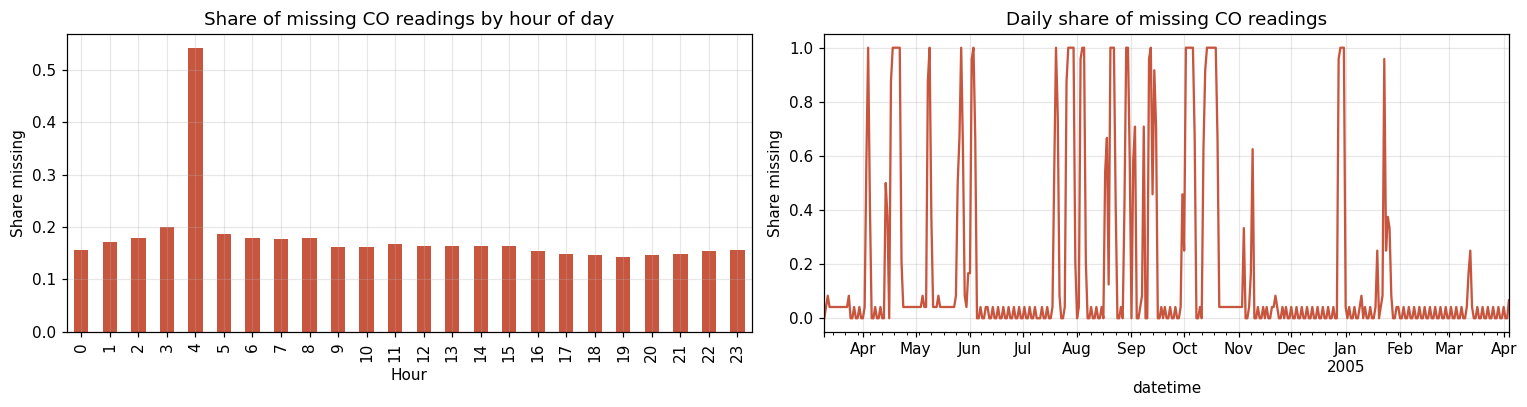

In [17]:
data = raw.replace(-200, np.nan)
missing = pd.DataFrame({"missing": data.isna().sum(), "share_%": (data.isna().mean() * 100).round(1)})
display(missing.sort_values("share_%", ascending=False))

def gap_lengths(s):
    isna = s.isna()
    runs = isna.groupby((isna != isna.shift()).cumsum()).sum()
    return runs[runs > 0]

co_gaps = gap_lengths(data[TARGET])
print(f"CO gaps: {len(co_gaps)} | median length {co_gaps.median():.0f} h | longest {co_gaps.max():.0f} h")
print(f"Gaps of 6 hours or less: {(co_gaps <= 6).sum()} (covering {co_gaps[co_gaps <= 6].sum()} h); "
      f"longer gaps cover {co_gaps[co_gaps > 6].sum()} h")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
data[TARGET].isna().groupby(data.index.hour).mean().plot.bar(ax=ax[0], color="#C8553D")
ax[0].set_title("Share of missing CO readings by hour of day"); ax[0].set_xlabel("Hour"); ax[0].set_ylabel("Share missing")
data[TARGET].isna().resample("D").mean().plot(ax=ax[1], color="#C8553D")
ax[1].set_title("Daily share of missing CO readings"); ax[1].set_ylabel("Share missing")
plt.tight_layout(); plt.savefig(FIG_DIR / "a3_missing.png"); plt.show()

**Findings.** `NMHC(GT)` is missing 90.2 % of the time, which makes it unusable. The target, `CO(GT)`, is missing 18.0 % of the time (1,683 hours), and NOx and NO2 about 17.5 %. All the other sensors and the weather readings are missing together for the same 366 hours (3.9 %), which points to the whole device being offline at those times.

Most CO gaps are short: the median gap is 1 hour, and 160 of the 187 gaps last 6 hours or less. However, the few long gaps (up to 173 hours, about a week) account for most of the missing hours (1,495 of 1,683). The hour-of-day chart also shows that CO is missing 54 % of the time at 04:00, against about 15 to 20 % at other hours, which suggests a regular daily maintenance or calibration slot for the reference analyser.

**How missing values were handled, and why**
1. **Dropped `NMHC(GT)`**: with 90 % missing, filling it would mean inventing most of the column.
2. **Filled gaps of 6 hours or less by time-based linear interpolation**: pollution changes gradually from one hour to the next, so a straight line between the readings on either side is a close estimate over a few hours, and it keeps the daily rhythm (including the regular 04:00 gap).
3. **Left longer gaps empty**: interpolating across several days would invent data the analyser never measured. These hours are excluded from model training instead.

Forward-filling was rejected because it repeats one value for hours and flattens the daily cycle; filling with the mean was rejected because it ignores the time of day and season.

In [18]:
MAX_GAP_HOURS = 6

def fill_short_gaps(s, max_gap=MAX_GAP_HOURS):
    isna = s.isna()
    run_len = isna.groupby((isna != isna.shift()).cumsum()).transform("sum")
    filled = s.interpolate(method="time", limit_area="inside")
    return s.where(~(isna & (run_len <= max_gap)), filled)

def clean(raw_df, max_gap=MAX_GAP_HOURS):
    df = raw_df.replace(-200, np.nan).drop(columns=["NMHC(GT)"], errors="ignore")
    return df.apply(fill_short_gaps, max_gap=max_gap)

df = clean(raw)
after = pd.DataFrame({"missing_before_%": (data.drop(columns="NMHC(GT)").isna().mean() * 100).round(1),
                      "missing_after_%": (df.isna().mean() * 100).round(1)})
display(after)

,missing_before_%,missing_after_%
CO(GT),18.0,16.0
PT08.S1(CO),3.9,3.8
C6H6(GT),3.9,3.8
PT08.S2(NMHC),3.9,3.8
NOx(GT),17.5,14.0
PT08.S3(NOx),3.9,3.8
NO2(GT),17.5,14.1
PT08.S4(NO2),3.9,3.8
PT08.S5(O3),3.9,3.8
T,3.9,3.8


After cleaning, missing CO falls from 18.0 % to 16.0 %, and NOx and NO2 from 17.5 % to about 14 %. What remains is almost entirely the long gaps, left empty on purpose.

### A4. Statistical distribution of the numerical columns

,count,mean,std,min,25%,50%,75%,max,skew
CO(GT),7862.0,2.12,1.46,0.10,1.00,1.8,2.80,11.90,1.37
PT08.S1(CO),9006.0,1100.12,217.16,647.00,937.00,1063.5,1232.00,2040.00,0.75
C6H6(GT),9006.0,10.09,7.45,0.10,4.40,8.2,14.00,63.70,1.36
PT08.S2(NMHC),9006.0,939.40,266.75,383.00,735.00,909.0,1117.00,2214.00,0.56
NOx(GT),8043.0,241.46,211.51,2.00,93.00,174.0,320.00,1479.00,1.74
PT08.S3(NOx),9006.0,835.21,256.77,322.00,658.00,805.0,969.00,2683.00,1.10
NO2(GT),8041.0,111.38,48.66,2.00,75.00,107.0,140.00,340.00,0.63
PT08.S4(NO2),9006.0,1456.40,345.99,551.00,1227.00,1463.0,1673.00,2775.00,0.20
PT08.S5(O3),9006.0,1023.47,398.97,221.00,732.25,963.5,1274.00,2523.00,0.63
T,9006.0,18.32,8.83,-1.90,11.80,17.8,24.40,44.60,0.31


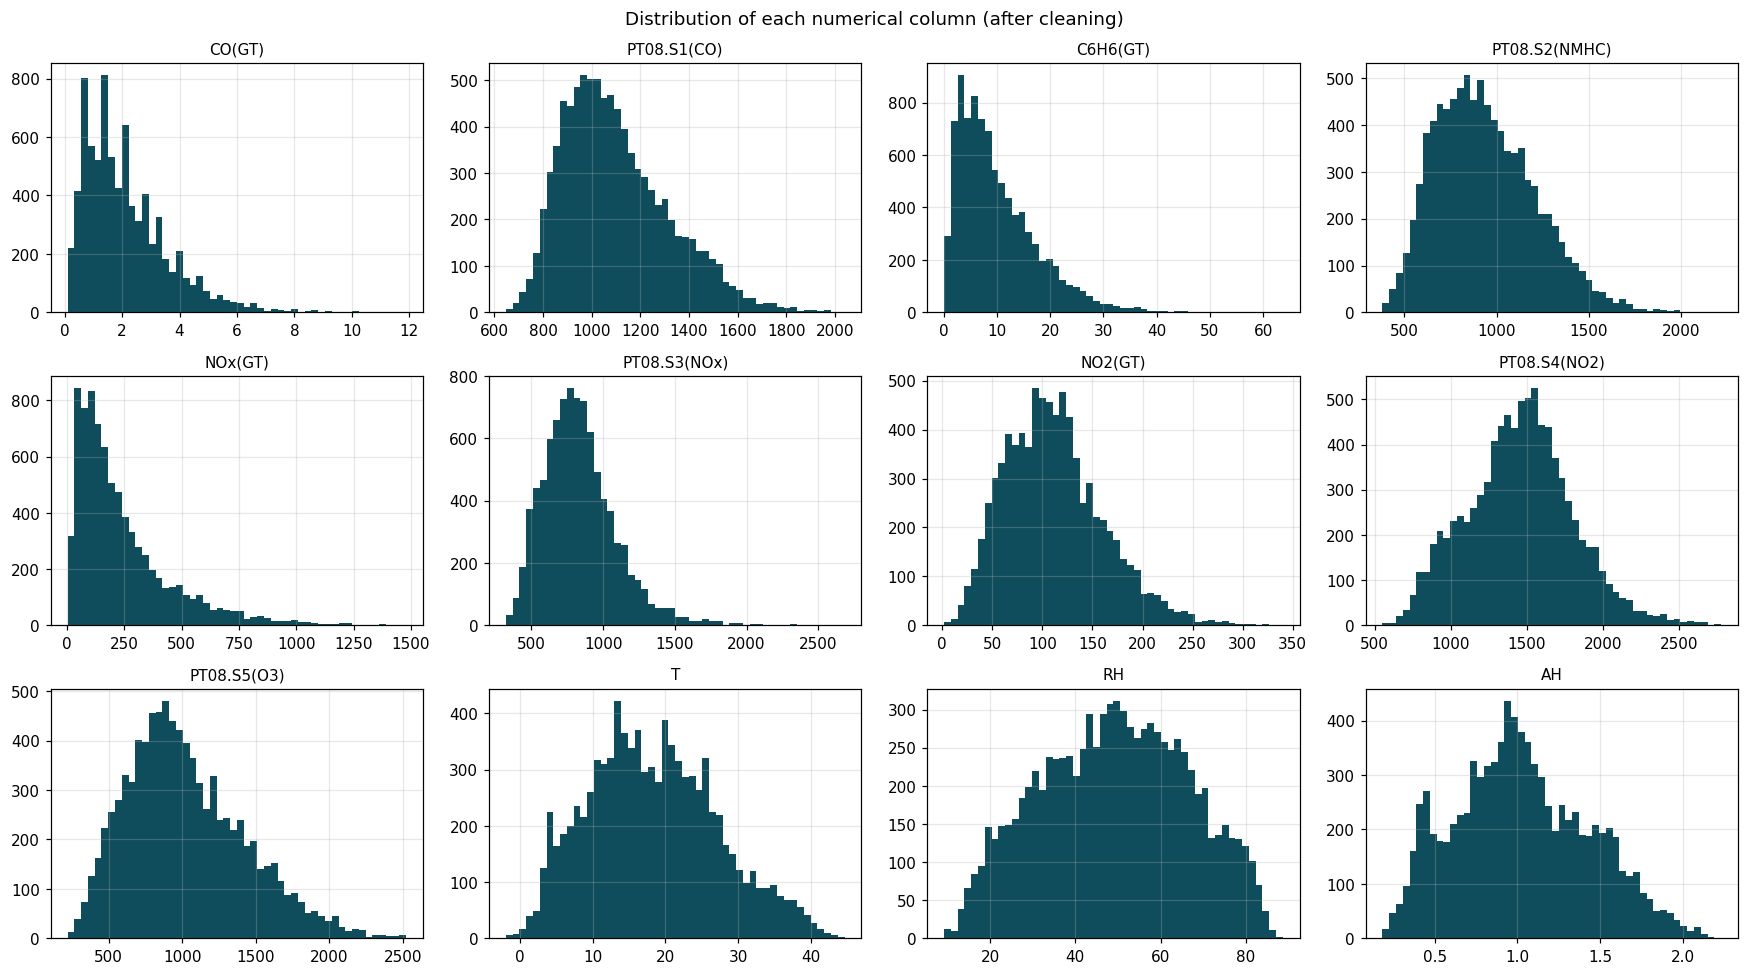

In [19]:
stats = df.describe().T
stats["skew"] = df.skew()
display(stats.round(2))

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col].dropna(), bins=50, color="#0F4C5C")
    ax.set_title(col, fontsize=10)
plt.suptitle("Distribution of each numerical column (after cleaning)")
plt.tight_layout(); plt.savefig(FIG_DIR / "a4_distributions.png"); plt.show()

**Findings.** CO averages **2.12 mg/m³** (median 1.8), ranging from 0.1 to 11.9. Its distribution is **right-skewed** (skew 1.37): most hours are fairly clean, with a long tail of high-pollution hours. NOx (skew 1.74) and benzene, C6H6 (1.36), share this shape, which is typical of traffic pollution with short rush-hour peaks. Temperature (mean 18.3 °C, from -1.9 to 44.6) and the humidity measures are close to symmetric. Because tree-based models do not assume a normal distribution, the skew was not transformed for the main model.

## B. Analytical questions
Six questions. **Q1 and Q5 use moving averages and moving windows; Q3 and Q4 use lagged features**, as the brief requires.

### Q1. Does CO show an increasing or decreasing trend over the year? (moving averages)

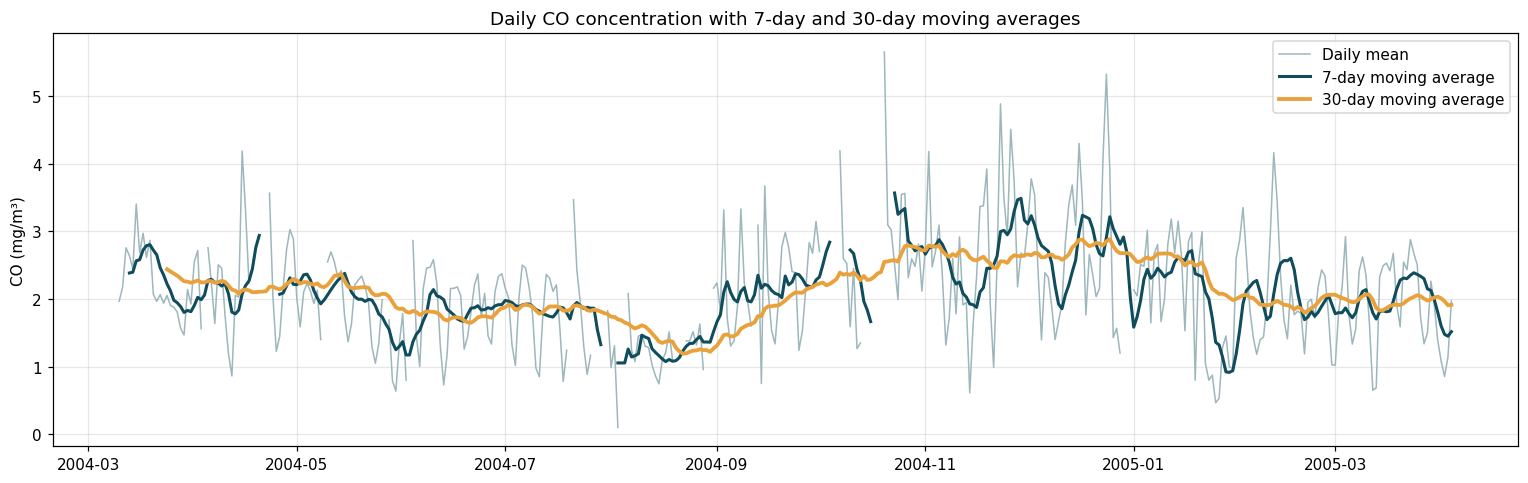

datetime
2004-03-01    2.25
2004-04-01    2.27
2004-05-01    1.87
2004-06-01    1.88
2004-07-01    1.77
2004-08-01    1.28
2004-09-01    2.16
2004-10-01    2.67
2004-11-01    2.65
2004-12-01    2.73
2005-01-01    2.09
2005-02-01    2.08
2005-03-01    2.00
2005-04-01    1.19
Freq: MS


In [20]:
daily = df[TARGET].resample("D").mean()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily, color="#9DB7BD", lw=1, label="Daily mean")
ax.plot(daily.rolling(7, min_periods=4).mean(), color="#0F4C5C", lw=2, label="7-day moving average")
ax.plot(daily.rolling(30, min_periods=15).mean(), color="#E9A23B", lw=2.5, label="30-day moving average")
ax.set_title("Daily CO concentration with 7-day and 30-day moving averages"); ax.set_ylabel("CO (mg/m³)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "q1_trend.png"); plt.show()
monthly = df[TARGET].resample("MS").mean()
print(monthly.round(2).to_string())

**Interpretation.** There is **no steady upward or downward trend** over the year. The 30-day moving average instead shows a **seasonal swing**: monthly mean CO falls from about 2.25 mg/m³ in March and April 2004 to its lowest point in **August (1.28)**, then rises to its highest in **October to December (about 2.7)**, before easing to about 2.0 in early 2005. The 7-day moving average shows short episodes of high pollution on top of this pattern. The August low likely reflects reduced traffic during the summer holiday period. (April 2005 covers only four days, so its mean of 1.19 is not reliable.)

### Q2. How does CO change through the day, and do weekdays differ from weekends?

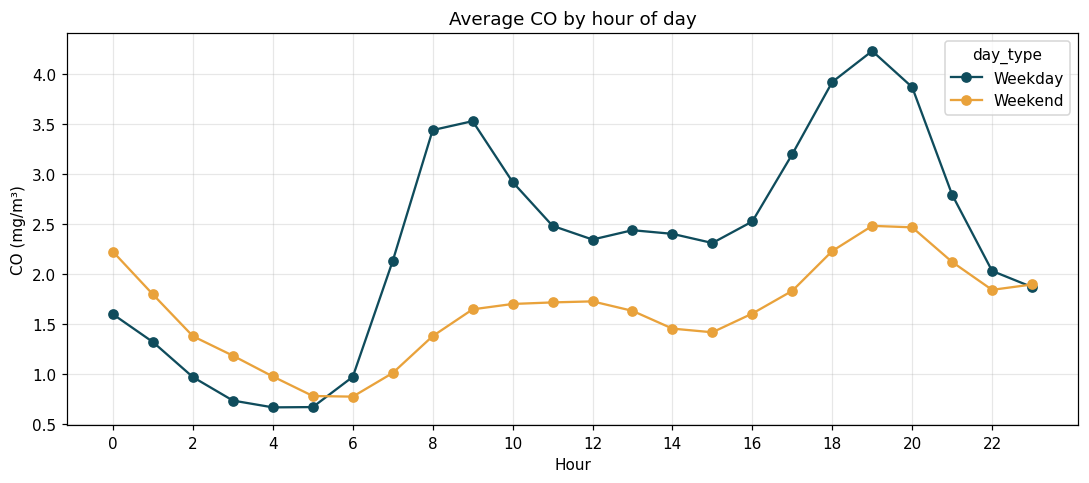

hour        0     1     2     3     4     5     6     7     8     9     10    11    12    13    14    15    16    17    18    19    20    21    22    23
day_type                                                                                                                                                
Weekday   1.60  1.32  0.97  0.74  0.67  0.67  0.97  2.13  3.44  3.53  2.92  2.48  2.35  2.44  2.40  2.31  2.53  3.20  3.92  4.23  3.87  2.79  2.03  1.87
Weekend   2.22  1.80  1.38  1.18  0.98  0.78  0.77  1.01  1.38  1.65  1.70  1.72  1.73  1.63  1.45  1.42  1.61  1.83  2.23  2.48  2.47  2.12  1.84  1.90


In [21]:
profile = df.assign(hour=df.index.hour, day_type=np.where(df.index.dayofweek >= 5, "Weekend", "Weekday"))
hourly = profile.groupby(["hour", "day_type"])[TARGET].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4.5))
hourly.plot(ax=ax, marker="o", color=["#0F4C5C", "#E9A23B"])
ax.set_title("Average CO by hour of day"); ax.set_xlabel("Hour"); ax.set_ylabel("CO (mg/m³)"); ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_daily_cycle.png"); plt.show()
print(hourly.round(2).T.to_string())

**Interpretation.** CO follows **traffic**. On weekdays it is lowest around 04:00 and 05:00 (0.67 mg/m³), rises sharply to a **morning peak at 08:00 to 09:00 (about 3.5)**, dips at midday, and reaches its **highest point in the evening at 19:00 (4.23)**. These two peaks match the morning and evening commutes. At weekends the pattern is much flatter: no sharp morning peak, and an evening high of only about 2.5. This confirms that hour of day and weekend status are useful features for the model.

### Q3. Are there lag effects: how strongly is CO related to its own past values? (lagged features)

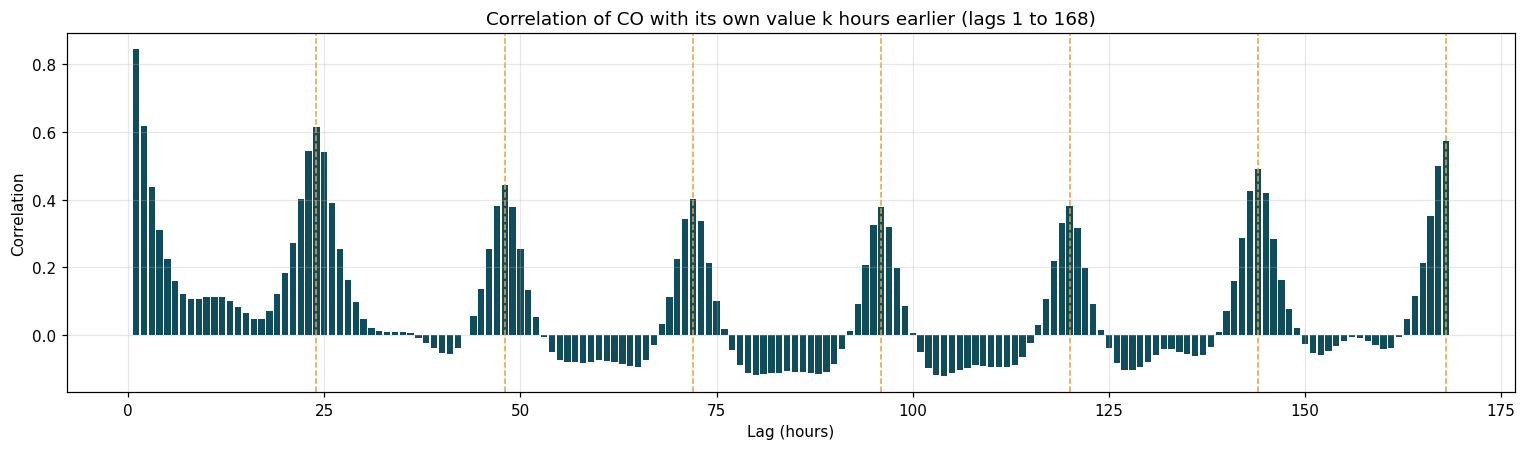

1      0.844
2      0.619
3      0.437
6      0.159
12     0.113
24     0.616
48     0.443
168    0.574


In [22]:
lags = range(1, 169)
acf = pd.Series([df[TARGET].autocorr(lag) for lag in lags], index=lags)
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.bar(acf.index, acf.values, color="#0F4C5C", width=0.8)
for d in (24, 48, 72, 96, 120, 144, 168):
    ax.axvline(d, color="#E9A23B", ls="--", lw=1)
ax.set_title("Correlation of CO with its own value k hours earlier (lags 1 to 168)"); ax.set_xlabel("Lag (hours)"); ax.set_ylabel("Correlation")
plt.tight_layout(); plt.savefig(FIG_DIR / "q3_lags.png"); plt.show()
print(acf.loc[[1, 2, 3, 6, 12, 24, 48, 168]].round(3).to_string())

**Interpretation.** CO has **strong memory**. Its correlation with the previous hour is **0.844**, dropping quickly to 0.619 at 2 hours and 0.159 at 6 hours. It then rises again to **0.616 at 24 hours** and **0.574 at 168 hours (one week)**, with peaks at every multiple of 24 hours. This shows a strong **daily cycle** and a **weekly cycle**: the level at this hour is similar to the same hour yesterday and the same hour last week. These findings decided the lagged features used in the model: the last few hours, plus the same hour on the previous day.

### Q4. Which simple rule predicts next hour's CO best: the last value or a moving average of recent hours? (lags and moving averages)
Each rule is used as a forecast of CO one hour ahead and scored with the mean absolute error (MAE).

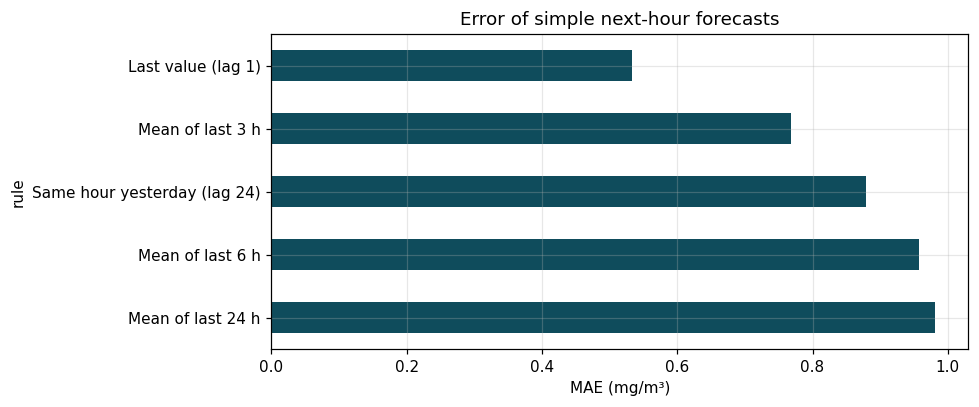

,MAE,correlation
rule,,
Last value (lag 1),0.533,0.844
Mean of last 3 h,0.768,0.688
Mean of last 6 h,0.957,0.531
Mean of last 24 h,0.981,0.445
Same hour yesterday (lag 24),0.879,0.616


In [23]:
nxt = df[TARGET].shift(-1)
rules = {"Last value (lag 1)": df[TARGET],
         "Mean of last 3 h": df[TARGET].rolling(3).mean(),
         "Mean of last 6 h": df[TARGET].rolling(6).mean(),
         "Mean of last 24 h": df[TARGET].rolling(24).mean(),
         "Same hour yesterday (lag 24)": df[TARGET].shift(23)}
rows = []
for name, pred_ in rules.items():
    ok = nxt.notna() & pred_.notna()
    rows.append({"rule": name, "MAE": mean_absolute_error(nxt[ok], pred_[ok]), "correlation": nxt[ok].corr(pred_[ok])})
naive = pd.DataFrame(rows).set_index("rule")
fig, ax = plt.subplots(figsize=(9, 3.8))
naive["MAE"].sort_values(ascending=False).plot.barh(ax=ax, color="#0F4C5C")
ax.set_title("Error of simple next-hour forecasts"); ax.set_xlabel("MAE (mg/m³)")
plt.tight_layout(); plt.savefig(FIG_DIR / "q4_naive_rules.png"); plt.show()
display(naive.round(3))

**Interpretation.** Simply using **the last hour's value** is the best simple forecast, with an MAE of **0.533 mg/m³** (correlation 0.844). Moving averages are worse, and get worse the longer the window: 0.768 for 3 hours, 0.957 for 6 hours and 0.981 for 24 hours, because averaging smooths away the rapid rises and falls of rush hours. The same hour yesterday (0.879) beats the long averages but not the last value. So moving averages alone are poor predictors, but they describe the recent level and volatility, so they were kept as **supporting features**, combined with the lags. The last-value rule also became the **baseline** the model must beat (experiment 0).

### Q5. Do the other variables move with CO, and is that relationship stable over time? (30-day moving correlation)

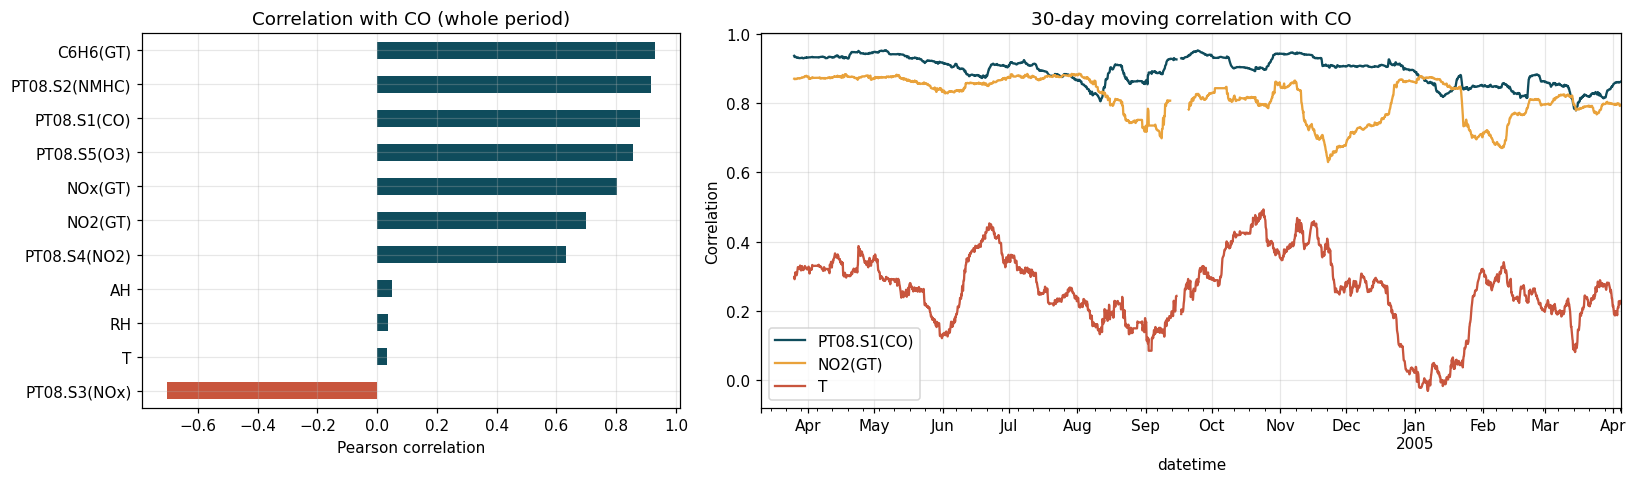

PT08.S3(NOx)    -0.705
T                0.031
RH               0.037
AH               0.050
PT08.S4(NO2)     0.632
NO2(GT)          0.698
NOx(GT)          0.801
PT08.S5(O3)      0.856
PT08.S1(CO)      0.881
PT08.S2(NMHC)    0.916
C6H6(GT)         0.931
30-day correlation with T ranges from -0.03 to 0.49


In [24]:
corr = df.corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
corr.plot.barh(ax=ax[0], color=np.where(corr > 0, "#0F4C5C", "#C8553D"))
ax[0].set_title("Correlation with CO (whole period)"); ax[0].set_xlabel("Pearson correlation")
window = 24 * 30
for col, colour in [("PT08.S1(CO)", "#0F4C5C"), ("NO2(GT)", "#E9A23B"), ("T", "#C8553D")]:
    df[TARGET].rolling(window, min_periods=window // 2).corr(df[col]).plot(ax=ax[1], label=col, color=colour)
ax[1].set_title("30-day moving correlation with CO"); ax[1].set_ylabel("Correlation"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "q5_correlations.png"); plt.show()
print(corr.round(3).to_string())
rc = df[TARGET].rolling(window, min_periods=window // 2).corr(df["T"])
print("30-day correlation with T ranges from", round(rc.min(), 2), "to", round(rc.max(), 2))

**Interpretation.** The other pollutant readings move closely with CO: **benzene (0.931)**, the NMHC sensor (0.916), the CO sensor (0.881), the O3 sensor (0.856) and **NOx (0.801)** are all strongly positive, because they come from the same source, traffic exhaust. The NOx sensor PT08.S3 is strongly **negative (-0.705)**, because its response falls as gas concentration rises. **Weather variables barely correlate** over the whole year (temperature 0.031, humidity 0.037). The 30-day moving correlation shows the pollutant relationships are steady over time, while the link with temperature is **unstable**, ranging from -0.03 to 0.49 depending on the month. Weather therefore adds little on its own.

### Q6. Is there a seasonal pattern, and does it follow temperature?

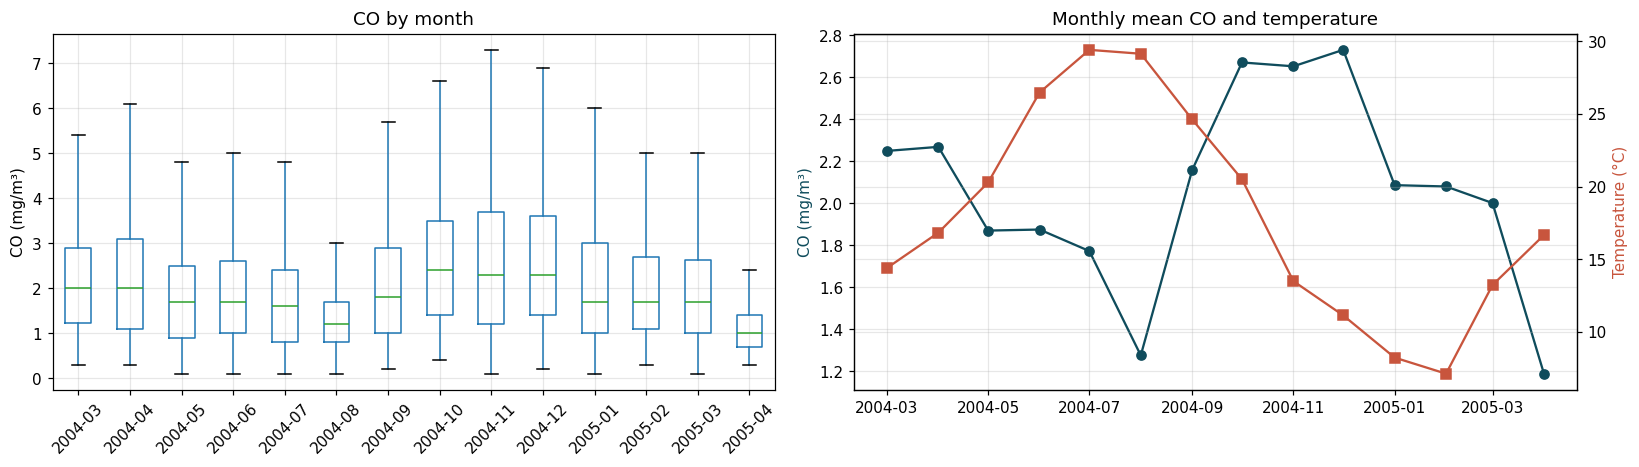

            CO(GT)      T
datetime                 
2004-03-01    2.25  14.39
2004-04-01    2.27  16.83
2004-05-01    1.87  20.28
2004-06-01    1.88  26.48
2004-07-01    1.77  29.41
2004-08-01    1.28  29.15
2004-09-01    2.16  24.62
2004-10-01    2.67  20.50
2004-11-01    2.65  13.49
2004-12-01    2.73  11.13
2005-01-01    2.09   8.22
2005-02-01    2.08   7.11
2005-03-01    2.00  13.22
2005-04-01    1.19  16.66
Correlation of monthly CO and temperature: -0.431


In [25]:
season = df.assign(month=df.index.to_period("M").astype(str))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
season.boxplot(column=TARGET, by="month", ax=ax[0], showfliers=False, rot=45)
ax[0].set_title("CO by month"); ax[0].set_xlabel(""); ax[0].set_ylabel("CO (mg/m³)")
mon = df[[TARGET, "T"]].resample("MS").mean()
ax2 = ax[1].twinx()
ax[1].plot(mon.index, mon[TARGET], marker="o", color="#0F4C5C", label="CO")
ax2.plot(mon.index, mon["T"], marker="s", color="#C8553D", label="Temperature")
ax[1].set_title("Monthly mean CO and temperature"); ax[1].set_ylabel("CO (mg/m³)", color="#0F4C5C"); ax2.set_ylabel("Temperature (°C)", color="#C8553D")
plt.suptitle(""); plt.tight_layout(); plt.savefig(FIG_DIR / "q6_seasonality.png"); plt.show()
print(mon.round(2).to_string())
print("Correlation of monthly CO and temperature:", round(mon[TARGET].corr(mon["T"]), 3))

**Interpretation.** Yes. CO is **higher in the cold months** and lower in summer: the correlation between monthly mean CO and monthly temperature is **-0.431**. October to December have the highest levels (about 2.7 mg/m³) at 11 to 20 °C, while August, the warmest period with July (about 29 °C), has the lowest (1.28). Likely reasons are more heating and traffic in autumn and winter, and a lower, more stable atmosphere that traps pollution near the ground in cold weather; the August low also matches the holiday traffic drop seen in Q1. The month was added as a feature so the model can learn this pattern.

## C. Training a forecasting model
### C1. Feature engineering
Every feature uses only information available at hour *t*; the target is CO at hour *t + 1*.

| Group | Features | Why |
|---|---|---|
| Lagged CO | CO at t, t-1, t-2, t-3, t-23 | Q3 showed strong short-term and daily memory |
| Moving averages | Mean of the last 3, 6 and 24 hours; standard deviation of the last 24 hours | Q4 showed smoothed history carries signal |
| Current readings | Sensor responses, NOx, NO2, benzene, temperature, humidity | Q5 showed strong links with CO |
| Calendar | Hour of day (as sine and cosine), day of week, weekend flag, month | Q2 and Q6 showed daily, weekly and seasonal cycles |

Rows whose features or target fall inside a long gap are dropped, so no invented values reach the model.

In [26]:
SENSORS = ["PT08.S1(CO)", "C6H6(GT)", "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)", "NO2(GT)",
           "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"]

def make_features(clean_df):
    co = clean_df[TARGET]
    X = pd.DataFrame(index=clean_df.index)
    X["co_t"] = co
    for k in (1, 2, 3, 23):
        X[f"co_lag_{k}"] = co.shift(k)
    for w in (3, 6, 24):
        X[f"co_ma_{w}"] = co.rolling(w).mean()
    X["co_std_24"] = co.rolling(24).std()
    for col in SENSORS:
        X[col] = clean_df[col]
    hour = clean_df.index.hour
    X["hour_sin"], X["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    X["dayofweek"] = clean_df.index.dayofweek
    X["is_weekend"] = (X["dayofweek"] >= 5).astype(int)
    X["month"] = clean_df.index.month
    y = co.shift(-1).rename("co_next_hour")
    ok = X.notna().all(axis=1) & y.notna()
    return X[ok], y[ok]

X, y = make_features(df)
FEATURES = list(X.columns)
print(f"Model rows: {len(X):,} of {len(df):,} hours | features: {len(FEATURES)}")

Model rows: 6,859 of 9,357 hours | features: 25


### C2. Chronological train and test split
A time series must not be shuffled: the model is trained on the past and tested on the future. The last 20 % of usable hours form the test set. Tuning uses `TimeSeriesSplit`, which also always validates on later data than it trains on.

In [27]:
split = int(len(X) * 0.8)
X_train, X_test, y_train, y_test = X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]
print(f"Train: {X_train.index.min():%d/%m/%Y} to {X_train.index.max():%d/%m/%Y} ({len(X_train):,} rows)")
print(f"Test:  {X_test.index.min():%d/%m/%Y} to {X_test.index.max():%d/%m/%Y} ({len(X_test):,} rows)")
CV = TimeSeriesSplit(n_splits=5)

def score(name, model, settings, X_te=None):
    X_te = X_test if X_te is None else X_te
    p = model.predict(X_te)
    return {"experiment": name, "settings": settings,
            "MAE": mean_absolute_error(y_test, p),
            "RMSE": mean_squared_error(y_test, p) ** 0.5,
            "R2": r2_score(y_test, p)}
results = []

Train: 11/03/2004 to 03/02/2005 (5,487 rows)
Test:  03/02/2005 to 04/04/2005 (1,372 rows)


### C3. Experiments and hyperparameter tuning
| Experiment | Model | Purpose |
|---|---|---|
| 0 | Persistence (next hour = this hour) | Baseline every model must beat |
| 1 | Ridge regression, alpha tuned by grid search | Linear model with all features |
| 2 | Random forest, randomised search | Non-linear ensemble (bagging) |
| 3 | Gradient boosting, randomised search | Non-linear ensemble (boosting) |
| 4 | Best of 2 and 3, without the other sensors | Do the external variables add value? |

All tuning uses 5-fold `TimeSeriesSplit` on the training period only, scored by MAE.

In [28]:
class Persistence:
    def predict(self, X_):
        return X_["co_t"].to_numpy()

results.append(score("Exp 0: Persistence baseline", Persistence(), "next hour = current hour"))

ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                     {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}, cv=CV, scoring="neg_mean_absolute_error")
ridge.fit(X_train, y_train)
results.append(score("Exp 1: Ridge regression", ridge.best_estimator_, f"alpha={ridge.best_params_['ridge__alpha']}"))

rf = RandomizedSearchCV(RandomForestRegressor(random_state=SEED, n_jobs=-1),
                        {"n_estimators": [200, 400], "max_depth": [8, 12, 16, None],
                         "min_samples_leaf": [1, 5, 10], "max_features": ["sqrt", 0.5, 1.0]},
                        n_iter=12, cv=CV, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
results.append(score("Exp 2: Random forest", rf.best_estimator_, json.dumps(rf.best_params_)))

hgb = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=SEED),
                         {"learning_rate": [0.03, 0.05, 0.1], "max_leaf_nodes": [15, 31, 63],
                          "min_samples_leaf": [10, 20, 50], "l2_regularization": [0.0, 0.1, 1.0],
                          "max_iter": [200, 400]},
                         n_iter=15, cv=CV, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
hgb.fit(X_train, y_train)
results.append(score("Exp 3: Gradient boosting", hgb.best_estimator_, json.dumps(hgb.best_params_)))
print("Cross-validated MAE  ridge:", round(-ridge.best_score_, 3), "| forest:", round(-rf.best_score_, 3),
      "| boosting:", round(-hgb.best_score_, 3))

Cross-validated MAE  ridge: 0.494 | forest: 0.476 | boosting: 0.454


In [29]:
best_search = rf if rf.best_score_ > hgb.best_score_ else hgb
best_name = "Random forest" if best_search is rf else "Gradient boosting"
own = [f for f in FEATURES if f not in SENSORS]
ablation = clone(best_search.best_estimator_).fit(X_train[own], y_train)
results.append(score(f"Exp 4: {best_name}, CO history and calendar only", ablation,
                     f"same settings as Exp {2 if best_search is rf else 3}, {len(own)} features", X_test[own]))

table = pd.DataFrame(results).set_index("experiment")
display(table[["settings", "MAE", "RMSE", "R2"]].round(3))

,settings,MAE,RMSE,R2
experiment,,,,
Exp 0: Persistence baseline,next hour = current hour,0.504,0.783,0.623
Exp 1: Ridge regression,alpha=100,0.415,0.603,0.776
Exp 2: Random forest,"{""n_estimators"": 200, ""min_samples_leaf"": 5, ""...",0.383,0.554,0.811
Exp 3: Gradient boosting,"{""min_samples_leaf"": 20, ""max_leaf_nodes"": 15,...",0.358,0.522,0.832
"Exp 4: Gradient boosting, CO history and calendar only","same settings as Exp 3, 14 features",0.358,0.531,0.826


**Interpretation of the experiment table**
- Every tuned model beats the **persistence baseline** (MAE 0.504, R² 0.623), so the models learn more than "next hour equals this hour".
- **Ridge regression** (MAE 0.415, R² 0.776) already improves strongly on the baseline. The best alpha was 100, the largest value in the grid, so even stronger regularisation could be tried.
- **Random forest** improves further (MAE 0.383, R² 0.811) by capturing non-linear effects such as the different rush-hour behaviour on weekdays.
- **Gradient boosting** is best on every measure: **MAE 0.357 mg/m³, RMSE 0.522, R² 0.832**. It reduces the baseline error by about 29 % ((0.504 - 0.357) / 0.504). It also had the best cross-validated MAE during tuning (0.453 against 0.476 for the forest and 0.494 for ridge), so it was selected without looking at the test set.
- **Experiment 4** removes the eleven other sensor and weather readings and keeps only CO's own history and the calendar. The error barely changes (MAE 0.359 against 0.357). For a one-hour-ahead forecast, **CO's own recent history carries almost all the information**; the other sensors add little, because their signal is already reflected in recent CO values. This is worth knowing for deployment: a simpler model needing only CO readings would work almost as well.

### C4. Best model on the test period
The final model is the experiment with the lowest cross-validated MAE among experiments 1 to 3, chosen on the training period only.

Selected on cross-validation: Exp 3: Gradient boosting


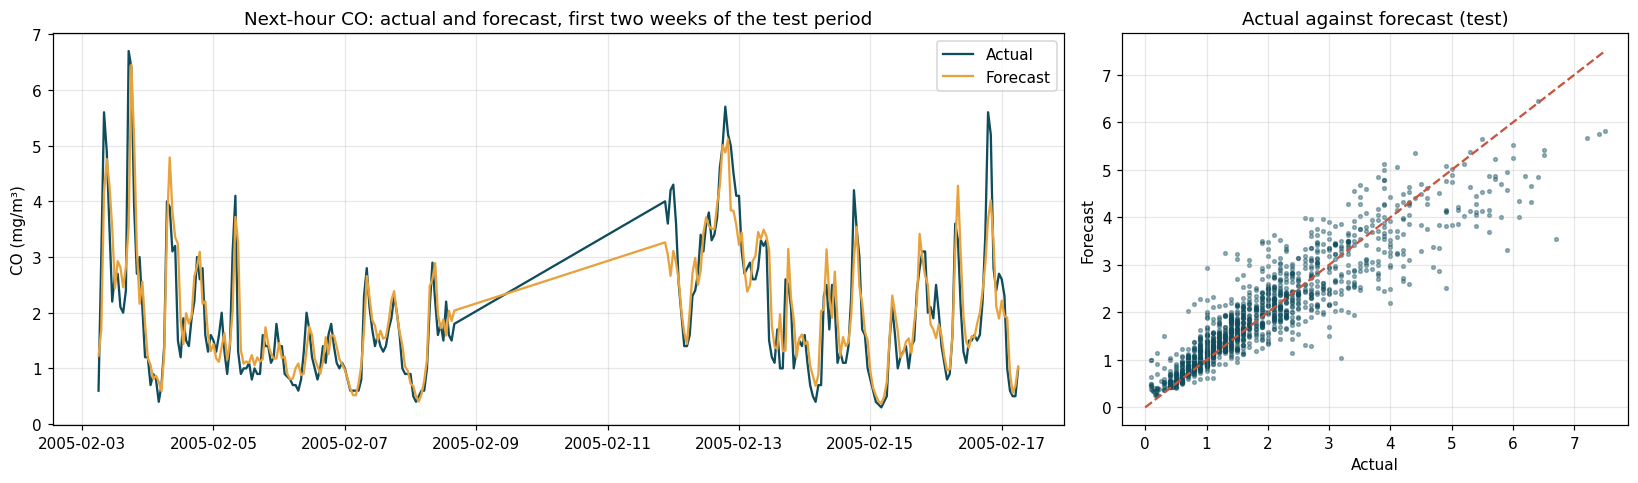

Test MAE 0.358 | persistence 0.504


In [30]:
searches = {"Exp 1: Ridge regression": ridge, "Exp 2: Random forest": rf, "Exp 3: Gradient boosting": hgb}
best = max(searches, key=lambda k: searches[k].best_score_)
final_model = searches[best].best_estimator_
pred = pd.Series(final_model.predict(X_test), index=X_test.index)
print("Selected on cross-validation:", best)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
first_two_weeks = slice(X_test.index[0], X_test.index[0] + pd.Timedelta(days=14))
ax[0].plot(y_test[first_two_weeks], color="#0F4C5C", label="Actual")
ax[0].plot(pred[first_two_weeks], color="#E9A23B", label="Forecast")
ax[0].set_title("Next-hour CO: actual and forecast, first two weeks of the test period"); ax[0].set_ylabel("CO (mg/m³)"); ax[0].legend()
ax[1].scatter(y_test, pred, s=6, alpha=0.4, color="#0F4C5C")
lim = [0, max(y_test.max(), pred.max())]
ax[1].plot(lim, lim, color="#C8553D", ls="--"); ax[1].set_xlabel("Actual"); ax[1].set_ylabel("Forecast"); ax[1].set_title("Actual against forecast (test)")
plt.tight_layout(); plt.savefig(FIG_DIR / "c4_forecast.png"); plt.show()

print(f"Test MAE {mean_absolute_error(y_test, pred):.3f} | persistence {mean_absolute_error(y_test, X_test['co_t']):.3f}")

**Interpretation.** On the test period (3 February to 4 April 2005, data the model never saw), the gradient boosting forecast follows the daily rush-hour peaks and night-time lows closely. The scatter plot lies around the diagonal, with the largest misses at the highest peaks, which the model tends to underestimate slightly, because sudden spikes are hard to predict from the previous hours. The straight line between 8 and 11 February is a long gap in the measurements: those hours were excluded rather than filled, so the plot simply joins the points on either side. The test period also lies in late winter and early spring, after the training period, so it checks that the model works on a later season, not just on data similar to its training set.

### C5. Saving the model and preprocessing settings for Task 4
The forecast script loads these two files and reuses `load_raw`, `clean` and `make_features` (also in `src/preprocessing.py`) so it prepares data exactly as here.

In [31]:
joblib.dump(final_model, MODEL_DIR / "co_forecast_model.joblib")
json.dump({"model": best, "target": TARGET, "horizon_hours": 1, "features": FEATURES,
           "max_gap_hours": MAX_GAP_HOURS, "dropped_columns": ["NMHC(GT)"], "missing_value_code": -200,
           "test_MAE": round(float(table.loc[best, "MAE"]), 4)},
          open(MODEL_DIR / "model_config.json", "w"), indent=2)
print(sorted(p.name for p in MODEL_DIR.iterdir()))

['co_forecast_model.joblib', 'model_config.json']
